# NF binned template: how to use `NFBinnedTemplate`

Component 01, DC4 511 keV binning. Expected counts per bin: $N_i = R \cdot T \cdot P_i$, with $P_i$ the NF density integrated over bin $i$, $R$ = model_counts / model_livetime (from the model FITS file), $T$ = live time in the time window (from the .ori file).

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup

Imports, then the inputs: model, orientation file, time window, binning and quadrature settings (the same as `src/compute_full_sky_template.py`).

In [2]:
import sys
from pathlib import Path
import numpy as np
import torch                                   # only to set the number of CPU threads
import healpy as hp                            # choose demo pixels by sky position
import astropy.units as u
from astropy.time import Time
from histpy import Axes, Axis, HealpixAxis     # the binning given to the class
from cosipy.spacecraftfile import SpacecraftHistory   # attitude + live time, for the Galactic step
from cosipy.data_io import BinnedData           # reads tmin, tmax from the DC4 binning yaml
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))     # project root, so `src` is importable
from src.nf_binned_template import NFBinnedTemplate, galactic_conversion_matrix   # what we demo

from src.plot_style import COLORS, set_global_style
set_global_style()                             # after the cosipy import

torch.set_num_threads(4)                       # fastest on your M5 (measured earlier)

%matplotlib inline


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



In [3]:
# NF model (component 01, version 3.00) and orientation file (attitude + live time)
MODEL_PATH = Path("../model/nfbackground_part-01_v3-00.fits")
ORI_PATH   = Path("../data/DC4_orientation.ori")

# DC4 time window [unix s], read from the DC4 binning yaml
BINNING_YAML = Path("/Users/maura/Documents/COSI/data-challenge-4/workflow/data/config/dataio_511.yaml")
cfg = BinnedData(input_yaml=str(BINNING_YAML))
TMIN, TMAX = cfg.tmin, cfg.tmax

# DC4 511 keV binning (dataio_511.yaml)
EM_EDGES_KEV  = [509.0, 513.0]          # 1 energy bin
PHI_EDGES_DEG = np.arange(0, 181, 3)    # 60 bins of 3 deg
NSIDE, SCHEME = 16, "ring"              # PsiChi: 3072 pixels

# Quadrature: FINAL settings of notebook 09
SUBPIXEL_LEVEL = 2                      # 4**k sky points per ordinary pixel
FINAL = dict(n_em_per_bin=4, n_phi_per_bin=4,
             em_breaks_kev=[511.0], phi_breaks_deg=[15.5, 16.0, 16.5, 17.0])

# Class options: the NFBinnedTemplate defaults (all fixes on), 
TEMPLATE_SETTINGS = dict(
    batch_size=4096,               # points per forward pass
    device="cpu",
    seam_delta_deg=0.2,            # chi = 0 strip
    polar_cap_deg=4.0,             # polar pixels: centre < 4 deg from a pole ...
    polar_subpixel_level=5,        # ... at level 5 ...
    pole_colat_deg=1.0,            # ... sub-pixels within 1 deg of the pole ...
    pole_subpixel_level=7,         # ... at level 7
    near_pole_cap_deg=10.0,        # pixels with centre < 10 deg from a pole ...
    near_pole_subpixel_level=3,    # ... at least level 3
)

# Attitude grouping for the Galactic rotation
SCATT_NSIDE = 32

print(f"time window: {TMIN} to {TMAX} s ({(TMAX - TMIN) / 86400:.1f} days)")


time window: 1835487300.036206 to 1843467254.887687 s (92.4 days)


## 2. Binning

The bins of the template as histpy `Axes`: Em (1 bin), Phi (60 bins), PsiChi (3072 HEALPix pixels).

In [4]:
# Binning given to the class: three axes with the labels it expects ("Em", "Phi", "PsiChi")
# This defines the bins of the template, using histpy objects, the same ones cosipy uses:
axes = Axes([Axis(EM_EDGES_KEV * u.keV, label="Em"),Axis(PHI_EDGES_DEG * u.deg, label="Phi"),HealpixAxis(nside=NSIDE, scheme=SCHEME, label="PsiChi")])

for ax in axes:
    print(f"{ax.label:6s}: {ax.nbins} bins")


Em    : 1 bins
Phi   : 60 bins
PsiChi: 3072 bins


## 3. Demo pixels

One pixel per sky rule of the class: ordinary (k = 2), on the χ = 0 seam, and near a pole (k = 3).

In [5]:
# One pixel per sky rule of the class (RING numbering, as the PsiChi axis)
PIXELS = {
    "ordinary":           hp.ang2pix(NSIDE, np.deg2rad(60), np.deg2rad(45)),   # far from poles and chi = 0
    "on chi = 0":         hp.ang2pix(NSIDE, np.deg2rad(90), np.deg2rad(0)),    # centre on the chi = 0 seam
    "near pole (< 10 deg)": hp.ang2pix(NSIDE, np.deg2rad(8), np.deg2rad(45)),  # gets level 3
}

# Where each pixel centre is: psi = colatitude, chi = longitude [deg]
for name, p in PIXELS.items():
    psi, chi = np.rad2deg(hp.pix2ang(NSIDE, p))
    print(f"{name:21s} pixel {p:4d}: psi {psi:6.2f} deg, chi {chi:6.2f} deg")


ordinary              pixel  680: psi  57.20 deg, chi  45.00 deg
on chi = 0            pixel 1440: psi  87.61 deg, chi   0.00 deg
near pole (< 10 deg)  pixel   13: psi   8.78 deg, chi  45.00 deg


## 4. Template object

Loads the NF model and its normalization $R$ = model_counts / model_livetime. No binning and no integral yet.

In [6]:
# Load the NF model once; no binning and no integral yet
template = NFBinnedTemplate(MODEL_PATH, **TEMPLATE_SETTINGS)

# Normalization read from the model file: R = model_counts / model_livetime
print(f"model version : {template.model_version}")
print(f"model_counts  : {template.model_counts:,.0f}")
print(f"model_livetime: {template.model_livetime:,.1f} s")
print(f"rate R        : {template.model_counts / template.model_livetime:.4f} events/s")

model version : 3.00
model_counts  : 97,554,902
model_livetime: 6,579,555.0 s
rate R        : 14.8270 events/s


## 5. Cost before computing

`n_evaluations` counts the density evaluations (Em × Phi × sky points) without computing anything.

In [7]:
# Number of density evaluations per pixel with the FINAL settings: nothing is computed yet
# (pixel 0 touches the pole: shown only to compare its cost, not computed in this notebook)
for name, p in {**PIXELS, "polar (not computed)": 0}.items():
    n = template.n_evaluations(axes, [p], subpixel_level=SUBPIXEL_LEVEL, **FINAL)
    print(f"{name:21s} pixel {p:4d}: {n:>9,} evaluations, ~{n / 7000:5.0f} s at ~7,000 evaluations/s")


ordinary              pixel  680:    32,768 evaluations, ~    5 s at ~7,000 evaluations/s
on chi = 0            pixel 1440:    32,768 evaluations, ~    5 s at ~7,000 evaluations/s
near pole (< 10 deg)  pixel   13:   131,072 evaluations, ~   19 s at ~7,000 evaluations/s
polar (not computed)  pixel    0: 3,786,752 evaluations, ~  541 s at ~7,000 evaluations/s


## 6. Expected counts, local frame

`get_binned_background` integrates the pixels still missing ($P_i$, stored in `template.probability`) and returns $N_i = R \cdot T \cdot P_i$ as a histpy `Histogram`.

In [8]:
# Expected counts N = R * T * P for the 3 pixels; integrates them first (~30 s)
pix = list(PIXELS.values())
N_local = template.get_binned_background(
    axes,                  # binning (Section 2)
    "local",               # spacecraft frame
    ORI_PATH,              # orientation file: gives the live time T
    TMIN, TMAX,            # time window (Section 1)
    pixels=pix,            # only our 3 pixels
    subpixel_level=SUBPIXEL_LEVEL, 
    **FINAL,
)

# P (stored in the template) and N (returned), summed over Em and Phi, for each pixel
P_per_pixel = template.probability.sum(axis=(0, 1))
N_per_pixel = N_local.project("PsiChi").contents

for name, p in PIXELS.items():
    print(f"{name:21s} pixel {p:4d}: level {template.subpixel_level_used[p]}, "
          f"P = {P_per_pixel[p]:.3e}, N = {N_per_pixel[p]:.1f} counts")


ordinary              pixel  680: level 2, P = 5.813e-07, N = 56.7 counts
on chi = 0            pixel 1440: level 2, P = 4.864e-07, N = 47.5 counts
near pole (< 10 deg)  pixel   13: level 3, P = 6.624e-07, N = 64.6 counts


## 7. Local → Galactic

$W[g, l]$ = live time during which Galactic pixel $g$ lies in local pixel $l$ (attitudes from the .ori file); $N_\mathrm{gal} = R \cdot P \, W^T$.

In [9]:
# Attitude and live time between TMIN and TMAX, from the orientation file
history = SpacecraftHistory.open(ORI_PATH).select_interval(Time(TMIN, format="unix"),
                                                           Time(TMAX, format="unix"))

# W[g, l] = live time [s] during which Galactic pixel g lies in local pixel l
W = galactic_conversion_matrix(history, NSIDE, nest=(SCHEME == "nested"), scatt_nside=SCATT_NSIDE)

print("W shape:", W.shape)                                   # (Galactic pixels, local pixels)
print(f"live time T: {history.livetime.to_value(u.s).sum():,.1f} s")
print(f"each row of W sums to T: {np.allclose(W.sum(axis=1), history.livetime.to_value(u.s).sum())}")


W shape: (3072, 3072)
live time T: 6,579,555.0 s
each row of W sums to T: True


### 7.1 One row of W

Where the Galactic centre was in the local frame during the time window.


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



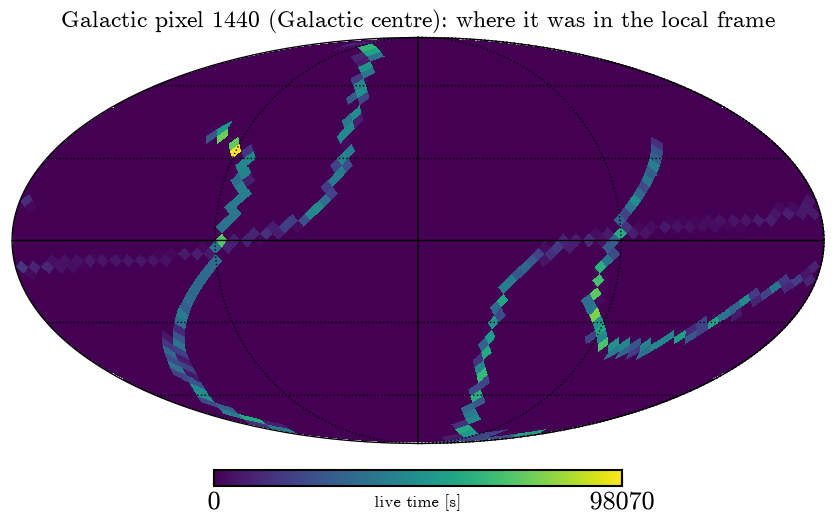

local pixels visited: 1036 of 3072


In [10]:
# Galactic centre (l = 0, b = 0): which Galactic pixel contains it
g = hp.ang2pix(NSIDE, 0.0, 0.0, lonlat=True)

# Row g of W: live time [s] the Galactic centre spent in each local pixel, drawn on the local sky
hp.mollview(W[g], unit="live time [s]",
            title=f"Galactic pixel {g} (Galactic centre): where it was in the local frame")
hp.graticule(dpar=30, dmer=90)
plt.show()

print(f"local pixels visited: {np.count_nonzero(W[g])} of {W.shape[1]}")


### 7.2 Rotating the 3 demo pixels

Where the counts of the 3 local pixels land in the Galactic sky. Not the Galactic template: that needs all 3072 local pixels.

local, 3 pixels : 168.8 counts
Galactic, all   : 170.2 counts


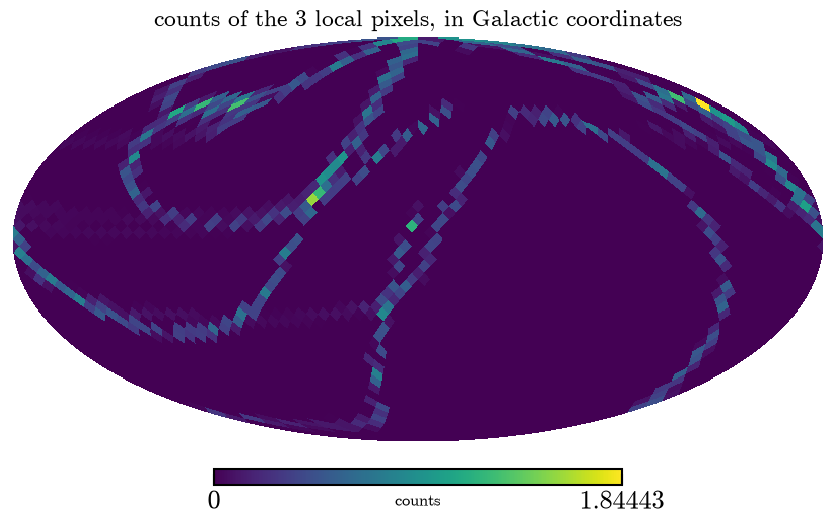

In [11]:
# Local P with only our 3 pixels; the other pixels (NaN) set to 0, so they contribute nothing
P_3 = np.nan_to_num(template.probability)

# Rotate: N_gal = R * P @ W.T  (same line as in get_binned_background)
rate = template.model_counts / template.model_livetime
N_gal_3 = rate * (P_3 @ W.T)                                  # (Em, Phi, Galactic pixels)

# Total counts: before (local) and after (Galactic) the rotation
print(f"local, 3 pixels : {N_per_pixel[list(PIXELS.values())].sum():.1f} counts")
print(f"Galactic, all   : {N_gal_3.sum():.1f} counts")

hp.mollview(N_gal_3.sum(axis=(0, 1)), unit="counts", title="counts of the 3 local pixels, in Galactic coordinates")
plt.show()


## 8. Full sky: run time

Evaluations per pixel group and the estimated time at `SPEED` evaluations/s (~7,000 on the MacBook, 4 threads).

In [12]:
# Speed of the machine [evaluations/s]: 7,000 = your MacBook (4 threads); set the cluster's value here
SPEED = 7000

# Distance of each pixel centre to the nearer pole, to split the sky by the class's rules
all_pixels = np.arange(hp.nside2npix(NSIDE))
psi = hp.pix2ang(NSIDE, all_pixels)[0]                        # colatitude [rad]
to_pole = np.minimum(psi, np.pi - psi)                        # distance to the nearer pole [rad]

groups = {
    "ordinary (k = 2)":         all_pixels[to_pole >= template.near_pole_cap_rad],
    "near pole (k = 3)":        all_pixels[(to_pole < template.near_pole_cap_rad) & (to_pole >= template.polar_cap_rad)],
    "polar (k = 5, 7 at pole)": all_pixels[to_pole < template.polar_cap_rad],
}

# Evaluations and time per group, then the whole sky (pixels=None)
for name, group in groups.items():
    n = template.n_evaluations(axes, group, subpixel_level=SUBPIXEL_LEVEL, **FINAL)
    print(f"{name:25s} {len(group):4d} pixels: {n:>12,} evaluations, ~{n / SPEED / 3600:4.1f} h")

n_all = template.n_evaluations(axes, None, subpixel_level=SUBPIXEL_LEVEL, **FINAL)
print(f"{'full sky':25s} {len(all_pixels):4d} pixels: {n_all:>12,} evaluations, ~{n_all / SPEED / 3600:4.1f} h")


ordinary (k = 2)          3024 pixels:   99,090,432 evaluations, ~ 3.9 h
near pole (k = 3)           40 pixels:    5,242,880 evaluations, ~ 0.2 h
polar (k = 5, 7 at pole)     8 pixels:   30,294,016 evaluations, ~ 1.2 h
full sky                  3072 pixels:  134,627,328 evaluations, ~ 5.3 h
